# VulHunter - Graph-Only (Enhanced Structural & Vulnerability Learning)

Chế độ `graph_only` nâng cấp: Không chỉ học từ AST Node Types đơn thuần mà còn tích hợp:
1. 🥇 **Enriched Node Text Features** (`node_texts` qua Subtoken Hash bảng 16,384 chiều hoặc CodeBERT word embeddings).
2. 🛡️ **Vulnerability-Aware Node Features** (`is_source`, `is_sink`, `is_sanitizer` annotations) từ PDG v2.
3. 🌐 **RGCN 4 lớp** với dropout tối ưu $0.2$, học sâu trên đồ thị phụ thuộc chương trình (Control Flow + Data Flow nâng cao + Call).

**Môi trường: Kaggle 2xT4, Internet ON, FP16 mixed precision.**


## 1. Setup Environment

In [1]:
import os
import subprocess
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'


import json, math, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, roc_auc_score, classification_report,
                             average_precision_score, precision_recall_curve, roc_curve)

sns.set_theme(style='whitegrid', context='notebook')
IS_KAGGLE = Path('/kaggle').exists()
print(f'IS_KAGGLE = {IS_KAGGLE}, PyTorch = {torch.__version__}')
if torch.cuda.is_available():
    print(f'GPUs = {torch.cuda.device_count()}')

# Clone VulHunter repo from GitHub
GITHUB_REPO = 'https://github.com/NhatWoan-20/VulHunter.git'
REPO_DIR = Path('/kaggle/working/VulHunter') if IS_KAGGLE else Path.cwd()

if not REPO_DIR.exists():
    print(f'Cloning VulHunter from GitHub to {REPO_DIR}...')
    result = subprocess.run(['git', 'clone', GITHUB_REPO, str(REPO_DIR)],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(f'Clone failed: {result.stderr}')
        raise RuntimeError('Failed to clone VulHunter repo')
    print('Clone successful!')

    # Install dependencies
    print('Installing dependencies...')
    subprocess.run(['pip', 'install', '-e', str(REPO_DIR), '-q'],
                   capture_output=True)

import sys
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print(f'Using repo: {REPO_DIR}')

# Test imports
import importlib
errors = []
modules_to_test = [
    'src.multitask.model',
    'src.utils.dataset',
    'src.utils.losses',
    'src.utils.metrics',
    'src.semantic.encoder',
]
for mod_name in modules_to_test:
    try:
        importlib.import_module(mod_name)
    except Exception as e:
        errors.append((mod_name, e))

if errors:
    raise ImportError('Modules failed')

from src.multitask.model import VulHunterModel, ModelOutput
from src.utils.dataset import VulHunterDataset, collate_fn
from src.utils.losses import BinaryClassificationLoss
from src.utils.metrics import binary_metrics, find_best_threshold
print('All imports OK')

IS_KAGGLE = True, PyTorch = 2.11.0+cu128
GPUs = 2
Cloning VulHunter from GitHub to /kaggle/working/VulHunter...
Clone successful!
Installing dependencies...
Using repo: /kaggle/working/VulHunter
All imports OK


In [2]:
if IS_KAGGLE:
    DATA_DIR = Path("/kaggle/input/datasets/nhat12k4/vulhunter-raw-data")
    GRAPH_PATH = Path("/kaggle/input/datasets/nhat12k4/vulhunter-raw-data/master_pdg.jsonl")
else:
    DATA_DIR = REPO_DIR / "data" / "splits"
    GRAPH_PATH = REPO_DIR / "data" / "final" / "master_pdg.jsonl"
    if not GRAPH_PATH.exists():
        GRAPH_PATH = REPO_DIR / "data" / "processed" / "master_pdg.jsonl"

TRAIN_JSONL = DATA_DIR / "train.jsonl"
VAL_JSONL   = DATA_DIR / "validation.jsonl"
TEST_JSONL  = DATA_DIR / "test.jsonl"
print(f"Train={TRAIN_JSONL.exists()}, Val={VAL_JSONL.exists()}, Test={TEST_JSONL.exists()}, Graph={GRAPH_PATH.exists()}")

def quick_eda(path, n=3000):
    rows = []
    with path.open() as f:
        for i, line in enumerate(f):
            if i >= n: break
            r = json.loads(line)
            rows.append({"binary_label": r.get("binary_label")})
    df = pd.DataFrame(rows)
    print(f"\nLoaded {len(df)} samples")
    print(f"Binary:\n{df['binary_label'].value_counts(normalize=True).round(3)}")
    pos_rate = df['binary_label'].mean()
    return df, 1 - pos_rate

eda_df, AUTO_FOCAL_ALPHA = quick_eda(TRAIN_JSONL)
print(f"\n🔍 auto focal_alpha = {AUTO_FOCAL_ALPHA:.3f}")


Train=True, Val=True, Test=True, Graph=True

Loaded 3000 samples
Binary:
binary_label
0    0.791
1    0.209
Name: proportion, dtype: float64

🔍 auto focal_alpha = 0.791


## 2. Configurations (Hyperparameters)

In [3]:
MODE = "graph_only"
MAX_LEN = 512
BATCH_SIZE = 256                # Tối ưu hóa GPU T4: batch 256 giúp bão hòa Tensor Cores, VRAM ~3GB, tốc độ x4-x5
GRAD_ACCUM = 1
EPOCHS = 35                    # Graph-only với Enriched Features hội tụ nhanh và ổn định hơn
LR_GRAPH = 4.0e-4              # R-GCN với enriched features và batch 256
LR_HEAD = 4.0e-4
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.05
FOCAL_ALPHA = AUTO_FOCAL_ALPHA
FOCAL_GAMMA = 2.0              # Focal gamma = 2.0 để tập trung vào mẫu khó
PATIENCE = 8
NUM_WORKERS = 4                # 2 workers nạp trước RAM song song (chống GPU starvation)
USE_AMP = True
TUNE_THRESHOLD = True

GRAPH_CFG = {
    "node_feature_dim": 128,
    "hidden_dim": 256,
    "output_dim": 256,
    "num_layers": 4,
    "num_heads": 8,
    "num_edge_types": 3,
    "dropout": 0.2,               # Giảm từ 0.3 -> 0.2 giúp đồ thị thưa học tốt hơn
    # 🥇 GP 1: Làm giàu đặc trưng Node bằng Subtoken Hashing
    # Tùy chọn: "hash" (GP1: nhanh & nhẹ) | "both" / "shared_codebert" (nạp CodeBERT embeddings) | "none"
    "node_encoder_type": "hash",
    "text_vocab_size": 16384,      # Bảng băm subtoken cho GP1
    "combine_mode": "add",         # Kết hợp Type + Text + Vul features
    # 🛡️ GP 4: Vulnerability-aware Node Features (Source / Sink / Sanitizer)
    "use_vul_features": True,
}
HEAD_CFG = {"binary": {"hidden_dim": 128, "dropout": 0.2}}
CKPT_DIR = Path("/kaggle/working/models/checkpoints/graph_only") if IS_KAGGLE else REPO_DIR / "models/checkpoints/graph_only"

RESUME_CKPT_PATH = Path("/kaggle/input/datasets/nhat12k4/graph-vul/best.pt")

CKPT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Mode: {MODE} | Batch Size: {BATCH_SIZE} | Workers: {NUM_WORKERS} | Node Encoder: {GRAPH_CFG['node_encoder_type']} | Vul Features: {GRAPH_CFG['use_vul_features']}")


Mode: graph_only | Batch Size: 256 | Workers: 4 | Node Encoder: hash | Vul Features: True


## 3. Initialize Model and DataLoader

In [4]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = VulHunterModel(mode=MODE, graph_config=GRAPH_CFG, head_config=HEAD_CFG)
model.to(device)

node_enc = getattr(getattr(model, 'graph_encoder', None), 'node_encoder_type', GRAPH_CFG.get('node_encoder_type', 'none'))
has_vul_f = getattr(getattr(model, 'graph_encoder', None), 'vul_features', None) is not None
print(f"âœ… Giai phap 1: Node Text Features ({node_enc}) da kich hoat")
print(f"âœ… Giai phap 4: Vulnerability Features (Source/Sink/Sanitizer: {has_vul_f}) da kich hoat")

for p in model.parameters():
    if p.requires_grad and p.dtype != torch.float32:
        p.data = p.data.float()
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"ðŸš€ [{MODE}] Trainable: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)\n")

# Zero-RAM Lazy Indexing cho DataLoaders (~15MB RAM total, chong tran RAM triet de)
train_ds = VulHunterDataset(data_path=TRAIN_JSONL, max_length=MAX_LEN, graph_data_path=GRAPH_PATH)
val_ds   = VulHunterDataset(data_path=VAL_JSONL,   max_length=MAX_LEN, graph_data_path=GRAPH_PATH)
test_ds  = VulHunterDataset(data_path=TEST_JSONL,  max_length=MAX_LEN, graph_data_path=GRAPH_PATH)

from functools import partial
collate_fn_padded = partial(collate_fn, pad_to_multiple_of=8)

loader_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
    "persistent_workers": (NUM_WORKERS > 0),
    "prefetch_factor": 2 if NUM_WORKERS > 0 else None,
}
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn_padded, **loader_kwargs)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE*2, shuffle=False, collate_fn=collate_fn_padded, **loader_kwargs)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE*2, shuffle=False, collate_fn=collate_fn_padded, **loader_kwargs)
print(f"Train: {len(train_ds):} | Val: {len(val_ds):} | Test: {len(test_ds):}")


âœ… Giai phap 1: Node Text Features (hash) da kich hoat
âœ… Giai phap 4: Vulnerability Features (Source/Sink/Sanitizer: True) da kich hoat
ðŸš€ [graph_only] Trainable: 3,248,516 / 3,248,516 (100.00%)

Train: 111902 | Val: 13987 | Test: 13990


## 4. Optimizer & Training Functions

In [5]:
criterion = BinaryClassificationLoss(focal_alpha=FOCAL_ALPHA, focal_gamma=FOCAL_GAMMA)
graph_params, head_params = [], []
for name, p in model.named_parameters():
    if not p.requires_grad: continue
    if "graph_encoder" in name: graph_params.append(p)
    else: head_params.append(p)
param_groups = []
if graph_params: param_groups.append({"params": graph_params, "lr": LR_GRAPH})
if head_params: param_groups.append({"params": head_params, "lr": LR_HEAD})
optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda s: min(1.0, s / max(1, int(len(train_loader) / GRAD_ACCUM * EPOCHS * WARMUP_RATIO)))
        if s < int(len(train_loader) / GRAD_ACCUM * EPOCHS * WARMUP_RATIO)
        else max(0.0, 0.5 * (1.0 + math.cos(math.pi * min(1.0, (s - int(len(train_loader) / GRAD_ACCUM * EPOCHS * WARMUP_RATIO)) / max(1, len(train_loader) / GRAD_ACCUM * EPOCHS - int(len(train_loader) / GRAD_ACCUM * EPOCHS * WARMUP_RATIO)))))),
)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and torch.cuda.is_available())
print(f"Optimizer: {len(graph_params)} graph + {len(head_params)} head")

Optimizer: 32 graph + 6 head


In [6]:
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch):
    model.train()
    total_loss = 0.0
    valid_steps = 0
    optimizer.zero_grad(set_to_none=True)
    t0 = time.time()
    
    pbar = tqdm(loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)
    for step, batch in enumerate(pbar):
        kwargs = {
            "node_types": batch["node_types"],
            "node_texts": batch.get("node_texts"),
            "node_is_source": batch.get("node_is_source"),
            "node_is_sink": batch.get("node_is_sink"),
            "node_is_sanitizer": batch.get("node_is_sanitizer"),
            "edge_index": batch["edge_index"].to(device, non_blocking=True),
            "edge_type": batch["edge_type"].to(device, non_blocking=True),
            "batch": batch["batch"].to(device, non_blocking=True),
        }
        targets = batch["binary_labels"].to(device, non_blocking=True)
        is_accumulating = ((step + 1) % GRAD_ACCUM != 0) and ((step + 1) != len(loader))
        
        if USE_AMP and torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(**kwargs)
                binary_logits = out.binary_logits if hasattr(out, 'binary_logits') else out[0]
                losses = criterion(binary_logits=binary_logits, binary_targets=targets)
                loss = losses["total"] / GRAD_ACCUM
            
            if not torch.isfinite(loss):
                print(f"\n⚠️ Canh bao: Loss khong huu han tai step {step+1}, bo qua batch!")
                optimizer.zero_grad(set_to_none=True)
                continue
                
            scaler.scale(loss).backward()
        else:
            out = model(**kwargs)
            binary_logits = out.binary_logits if hasattr(out, 'binary_logits') else out[0]
            losses = criterion(binary_logits=binary_logits, binary_targets=targets)
            loss = losses["total"] / GRAD_ACCUM
            
            if not torch.isfinite(loss):
                print(f"\n⚠️ Canh bao: Loss khong huu han tai step {step+1}, bo qua batch!")
                optimizer.zero_grad(set_to_none=True)
                continue
                
            loss.backward()
            
        if not is_accumulating:
            if USE_AMP and scaler is not None:
                scaler.unscale_(optimizer)
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                if torch.isfinite(grad_norm):
                    scaler.step(optimizer)
                else:
                    optimizer.zero_grad(set_to_none=True)
                scaler.update()
            else:
                grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                if torch.isfinite(grad_norm):
                    optimizer.step()
                else:
                    optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            
        total_loss += loss.item() * GRAD_ACCUM
        valid_steps += 1
        if (step + 1) % 10 == 0 or step == len(loader) - 1:
            avg_loss = total_loss / max(valid_steps, 1)
            pbar.set_postfix({'loss': f"{avg_loss:.4f}", 'lr': f"{optimizer.param_groups[0]['lr']:.2e}"})
            
    return total_loss / max(valid_steps, 1)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    y_true, y_prob = [], []
    
    pbar = tqdm(loader, desc="Evaluating", leave=False)
    for batch in pbar:
        kwargs = {
            "node_types": batch["node_types"],
            "node_texts": batch.get("node_texts"),
            "node_is_source": batch.get("node_is_source"),
            "node_is_sink": batch.get("node_is_sink"),
            "node_is_sanitizer": batch.get("node_is_sanitizer"),
            "edge_index": batch["edge_index"].to(device),
            "edge_type": batch["edge_type"].to(device),
            "batch": batch["batch"].to(device),
        }
        if USE_AMP and torch.cuda.is_available():
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = model(**kwargs)
        else:
            out = model(**kwargs)
            
        binary_logits = out.binary_logits if hasattr(out, 'binary_logits') else out[0]
        p = torch.sigmoid(binary_logits.squeeze(-1).float())
        p = torch.nan_to_num(p, nan=0.5)
        
        y_true.extend(batch["binary_labels"].tolist())
        y_prob.extend(p.cpu().tolist())
    return np.array(y_true), np.array(y_prob)

print("✅ Functions defined (with Numerical Stability Guards & Vulnerability Features)")


✅ Functions defined (with Numerical Stability Guards & Vulnerability Features)


In [7]:
# Main training
import math
import shutil
import torch.nn as nn
from pathlib import Path
# Đảm bảo thư mục lưu checkpoint tồn tại
CKPT_DIR.mkdir(parents=True, exist_ok=True)
start_epoch = 0
best_f1 = 0.0
best_threshold = 0.5
patience_counter = 0
history = []

# --- 1. KHỐI NẠP CHECKPOINT TỪ CELL PHÍA TRÊN ---
resume_path = globals().get("RESUME_CKPT_PATH", None)
if resume_path is not None and Path(resume_path).exists():
    resume_file = Path(resume_path)
    print(f"🔄 PHÁT HIỆN CHECKPOINT CŨ: Đang nạp từ {resume_file}...")
    ckpt = torch.load(resume_file, map_location=device, weights_only=False)
    # 1.1. Khôi phục trọng số Model
    base_model = model.module if isinstance(model, nn.DataParallel) else model
    if "model_state_dict" in ckpt:
        missing, unexpected = base_model.load_state_dict(ckpt["model_state_dict"], strict=False)
        print(f"  ✅ Đã nạp trọng số Model thành công (missing: {len(missing)}).")
    # Đảm bảo file best.pt luôn sẵn sàng trong CKPT_DIR cho các bước Test / Save summary sau này
    target_best = CKPT_DIR / "best.pt"
    if resume_file.resolve() != target_best.resolve():
        shutil.copy2(resume_file, target_best)
        print(f"  💾 Đã đồng bộ checkpoint sang {target_best}")
    # 1.2. Khôi phục Epoch và các chỉ số thống kê
    start_epoch = ckpt.get("epoch", 0)
    best_f1 = ckpt.get("best_f1", 0.0)
    best_threshold = ckpt.get("best_threshold", 0.5)
    # Vì nạp từ checkpoint tốt nhất, ta reset patience_counter về 0 để có đủ cơ hội bứt phá
    patience_counter = 0
    history = list(ckpt.get("history", []))
    # 1.3. Khôi phục Optimizer State (nếu có)
    if "optimizer_state_dict" in ckpt and ckpt["optimizer_state_dict"] is not None:
        try:
            optimizer.load_state_dict(ckpt["optimizer_state_dict"])
            print("  ✅ Đã khôi phục Optimizer state.")
        except Exception as e:
            print(f"  ℹ️ Khởi tạo lại Optimizer state mới: {e}")
    # 1.4. Khôi phục hoặc TUA NHANH Scheduler về đúng epoch hiện tại
    if "scheduler_state_dict" in ckpt and ckpt["scheduler_state_dict"] is not None:
        try:
            scheduler.load_state_dict(ckpt["scheduler_state_dict"])
            print("  ✅ Đã khôi phục Scheduler state từ checkpoint.")
        except Exception:
            pass
    elif start_epoch > 0:
        steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
        steps_done = min(start_epoch * steps_per_epoch, steps_per_epoch * EPOCHS)
        for _ in range(steps_done):
            scheduler.step()
        current_lr = optimizer.param_groups[0]["lr"]
        print(f"  ⏩ Đã đồng bộ LR Scheduler tới step {steps_done} (LR hiện tại: {current_lr:.2e}).")
    # 1.5. Khôi phục FP16 GradScaler (nếu có)
    if scaler is not None and "scaler_state_dict" in ckpt and ckpt["scaler_state_dict"] is not None:
        try:
            scaler.load_state_dict(ckpt["scaler_state_dict"])
            print("  ✅ Đã khôi phục FP16 GradScaler.")
        except Exception:
            pass
    print(f"  🚀 TIẾP TỤC TỪ: Epoch {start_epoch + 1}/{EPOCHS} (Best Val F1 trước: {best_f1:.4f}, thr={best_threshold:.2f})\n")
    if start_epoch >= EPOCHS:
        print(f"⚡ Đã hoàn thành đủ {start_epoch}/{EPOCHS} epochs ở phiên trước!")
        print("➡️ Bỏ qua vòng lặp huấn luyện, chuyển thẳng xuống phần Đánh giá Test Set.\n")
else:
    print("🆕 Không tìm thấy checkpoint cũ, bắt đầu huấn luyện từ Epoch 1.\n")

for epoch in range(start_epoch, EPOCHS):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, epoch)
    val_y, val_prob = evaluate(model, val_loader)
    elapsed = time.time() - t0

    if TUNE_THRESHOLD and len(val_y) > 0:
        thr, m = find_best_threshold(val_y, val_prob)
    else:
        thr = 0.5
        preds = (val_prob >= thr).astype(int)
        m = binary_metrics(val_y, preds, val_prob, threshold=thr)
    val_f1 = m.f1

    print(f"\nEpoch {epoch+1}/{EPOCHS} ({elapsed:.1f}s) | Train loss={train_loss:.4f} | Val F1={val_f1:.4f} | P={m.precision:.4f} | R={m.recall:.4f} | AUC={m.auc:.4f} | thr={thr:.2f}")

    history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_f1": val_f1, "val_metrics": m.to_dict(), "threshold": thr, "elapsed": elapsed})

    base_model = model.module if isinstance(model, nn.DataParallel) else model
    trainable_names = {n for n, p in base_model.named_parameters() if p.requires_grad}
    sd = {k: v.cpu() for k, v in base_model.state_dict().items() if k in trainable_names}

    checkpoint_data = {
        "epoch": epoch + 1,
        "model_state_dict": sd,
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict() if scaler else None,
        "best_f1": best_f1,
        "best_threshold": best_threshold,
        "patience_counter": patience_counter,
        "config": {"mode": MODE, "model": {"graph": GRAPH_CFG, "heads": HEAD_CFG}},
        "history": history,
    }

    torch.save(checkpoint_data, CKPT_DIR / "last.pt")
    
    if val_f1 > best_f1:
        best_f1 = val_f1; best_threshold = thr; patience_counter = 0
        checkpoint_data["best_f1"] = best_f1
        checkpoint_data["best_threshold"] = best_threshold
        checkpoint_data["patience_counter"] = 0
        torch.save(checkpoint_data, CKPT_DIR / "best.pt")
        print(f"  ✅ Saved best (F1={best_f1:.4f}, thr={best_threshold:.2f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹️ Early stopping sau {PATIENCE} epochs không cải thiện.")
            break

print(f"\n✅ Best Val F1 = {best_f1:.4f} @ thr {best_threshold:.2f}")


🔄 PHÁT HIỆN CHECKPOINT CŨ: Đang nạp từ /kaggle/input/datasets/nhat12k4/graph-vul/best.pt...
  ✅ Đã nạp trọng số Model thành công (missing: 0).
  💾 Đã đồng bộ checkpoint sang /kaggle/working/models/checkpoints/graph_only/best.pt
  ⏩ Đã đồng bộ LR Scheduler tới step 7008 (LR hiện tại: 2.44e-04).
  🚀 TIẾP TỤC TỪ: Epoch 17/35 (Best Val F1 trước: 0.6167, thr=0.55)



Epoch 17/35 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/28 [00:00<?, ?it/s]


Epoch 17/35 (1984.7s) | Train loss=0.0243 | Val F1=0.6144 | P=0.5195 | R=0.7519 | AUC=0.8529 | thr=0.60


Epoch 18/35 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/28 [00:00<?, ?it/s]


Epoch 25/35 (1987.0s) | Train loss=0.0205 | Val F1=0.6142 | P=0.5087 | R=0.7748 | AUC=0.8507 | thr=0.45


Epoch 26/35 [Train]:   0%|          | 0/438 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/28 [00:00<?, ?it/s]


Epoch 26/35 (1987.6s) | Train loss=0.0203 | Val F1=0.6139 | P=0.5111 | R=0.7685 | AUC=0.8484 | thr=0.55

⏹️ Early stopping sau 8 epochs không cải thiện.

✅ Best Val F1 = 0.6172 @ thr 0.55


## 5. Test Evaluation & Diagnostics

Evaluating:   0%|          | 0/28 [00:00<?, ?it/s]


📊 GRAPH-ONLY — KẾT QUẢ ĐÁNH GIÁ TEST SET
  precision                : 0.5100
  recall                   : 0.7570
  f1                       : 0.6094
  accuracy                 : 0.7906
  support                  : 13990
  threshold                : 0.5500
  auc                      : 0.8452
  pr_auc                   : 0.5420
  mcc                      : 0.4909

📋 Báo cáo phân loại chi tiết (Classification Report):
                             precision    recall  f1-score   support

      Label 0 (Benign/Safe)     0.9228    0.7998    0.8569     10970
Label 1 (Defect/Vulnerable)     0.5100    0.7570    0.6094      3020

                   accuracy                         0.7906     13990
                  macro avg     0.7164    0.7784    0.7332     13990
               weighted avg     0.8337    0.7906    0.8035     13990



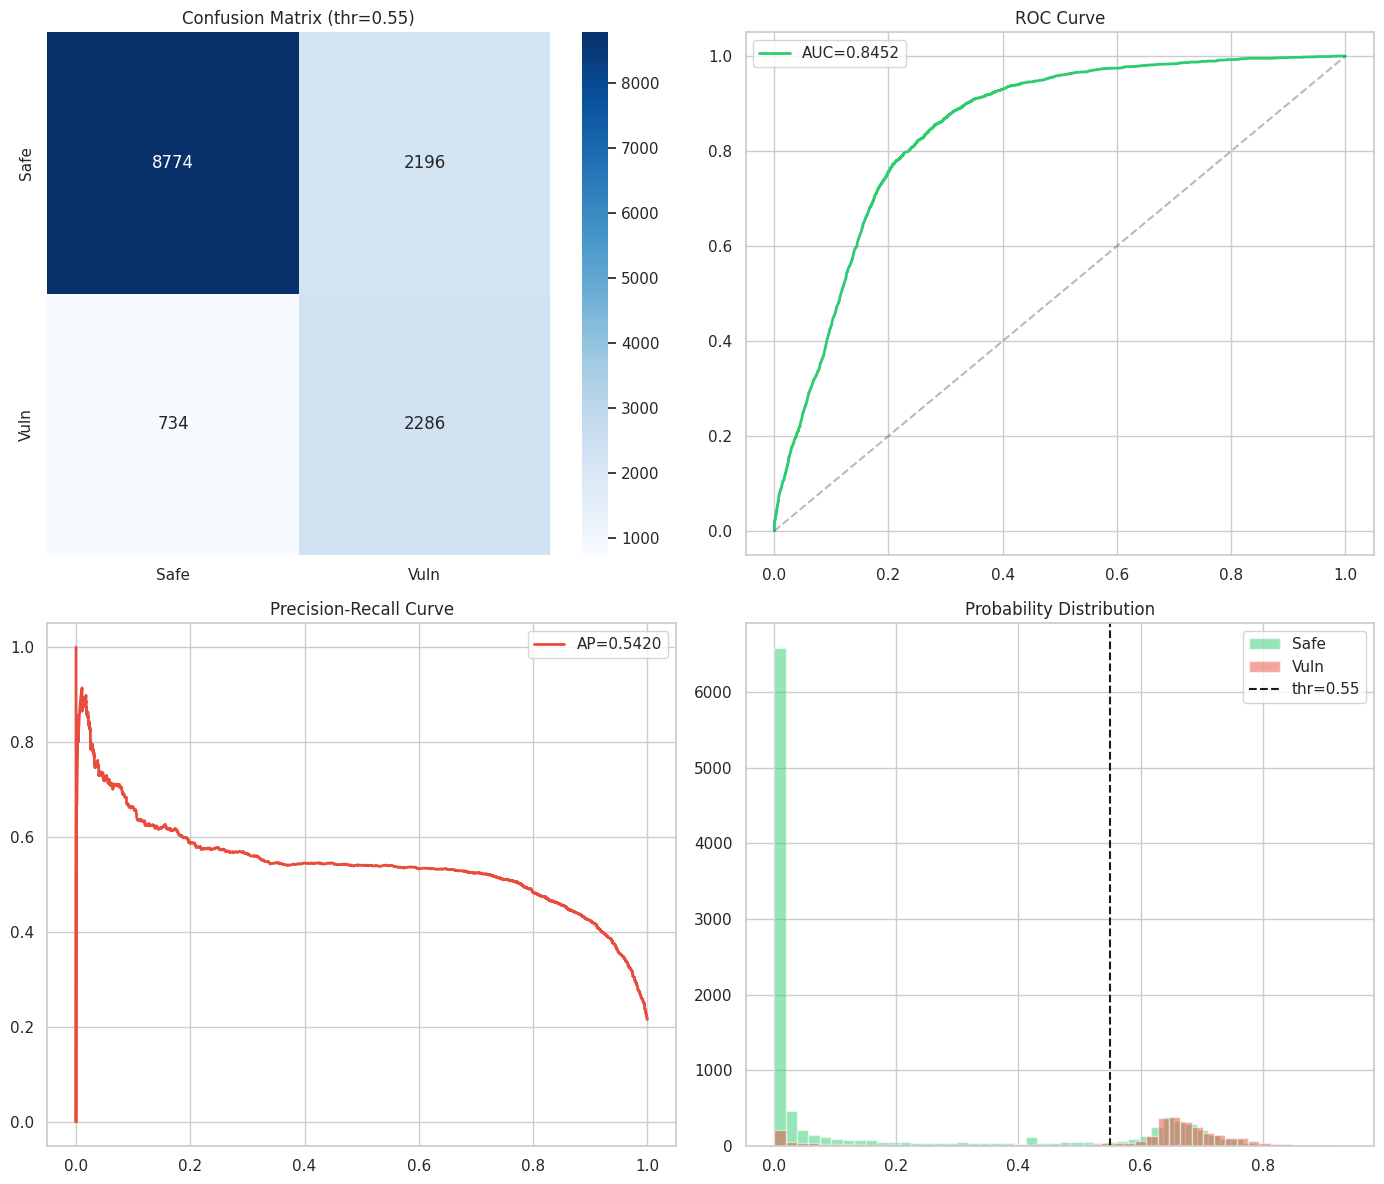

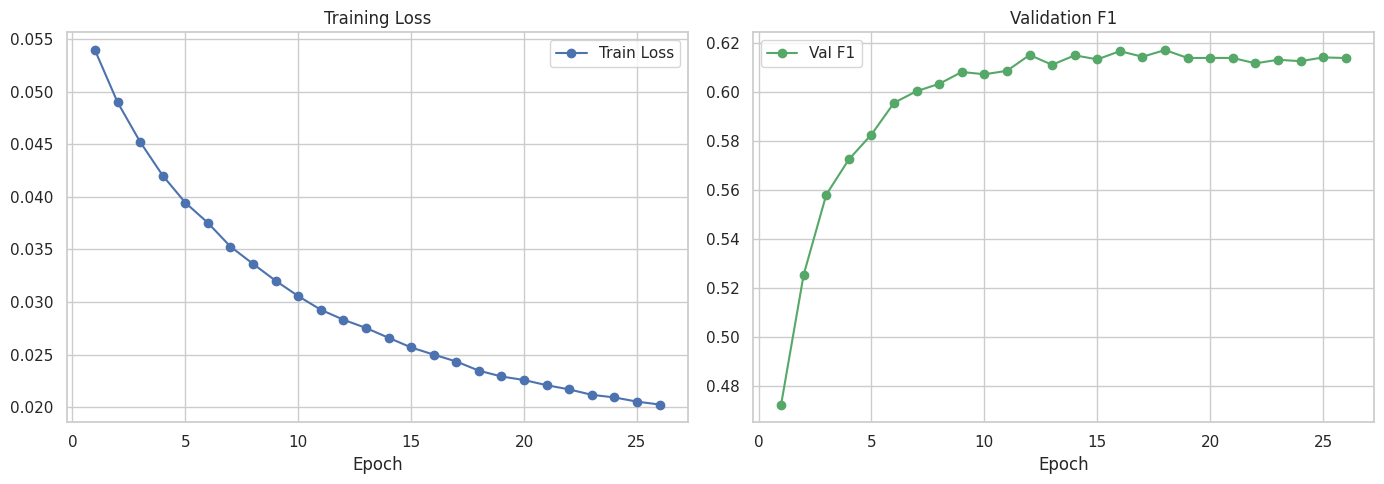

In [8]:
test_y, test_prob = evaluate(model, test_loader)
test_pred = (test_prob >= best_threshold).astype(int)
test_metrics = binary_metrics(test_y, test_pred, test_prob, threshold=best_threshold)

print("\n" + "=" * 60)
print("📊 GRAPH-ONLY — KẾT QUẢ ĐÁNH GIÁ TEST SET")
print("=" * 60)
for k, v in test_metrics.to_dict().items():
    if isinstance(v, float):
        print(f"  {k:<25}: {v:.4f}")
    else:
        print(f"  {k:<25}: {v}")
print("=" * 60)

print("\n📋 Báo cáo phân loại chi tiết (Classification Report):")
print(classification_report(
    test_y, test_pred,
    target_names=["Label 0 (Benign/Safe)", "Label 1 (Defect/Vulnerable)"],
    digits=4,
))

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Confusion Matrix
cm = confusion_matrix(test_y, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0, 0], xticklabels=["Safe", "Vuln"], yticklabels=["Safe", "Vuln"])
axes[0, 0].set_title(f"Confusion Matrix (thr={best_threshold:.2f})")

# ROC Curve
if len(np.unique(test_y)) > 1:
    fpr, tpr, _ = roc_curve(test_y, test_prob)
    axes[0, 1].plot(fpr, tpr, label=f"AUC={roc_auc_score(test_y, test_prob):.4f}", color="#2ecc71", lw=2)
    axes[0, 1].plot([0, 1], [0, 1], "k--", alpha=0.3)
    axes[0, 1].legend()
    axes[0, 1].set_title("ROC Curve")

# Precision-Recall Curve
p, r, _ = precision_recall_curve(test_y, test_prob)
axes[1, 0].plot(r, p, label=f"AP={average_precision_score(test_y, test_prob):.4f}", color="#e74c3c", lw=2)
axes[1, 0].legend()
axes[1, 0].set_title("Precision-Recall Curve")

# Probability Distribution
axes[1, 1].hist(test_prob[test_y == 0], bins=50, alpha=0.5, label="Safe", color="#2ecc71")
axes[1, 1].hist(test_prob[test_y == 1], bins=50, alpha=0.5, label="Vuln", color="#e74c3c")
axes[1, 1].axvline(best_threshold, color="k", linestyle="--", label=f"thr={best_threshold:.2f}")
axes[1, 1].legend()
axes[1, 1].set_title("Probability Distribution")

plt.tight_layout()
plt.savefig(CKPT_DIR / "diagnostics.png", dpi=120)
plt.show()

# Training History Plot (thêm vào vì semantic có)
if history:
    fig2, ax2 = plt.subplots(1, 2, figsize=(14, 5))
    epochs_done = [h["epoch"] for h in history]
    ax2[0].plot(epochs_done, [h["train_loss"] for h in history], "b-o", label="Train Loss")
    ax2[0].set_title("Training Loss")
    ax2[0].set_xlabel("Epoch")
    ax2[0].legend()
    ax2[1].plot(epochs_done, [h["val_f1"] for h in history], "g-o", label="Val F1")
    ax2[1].set_title("Validation F1")
    ax2[1].set_xlabel("Epoch")
    ax2[1].legend()
    plt.tight_layout()
    plt.savefig(CKPT_DIR / "training_history.png", dpi=120)
    plt.show()



In [9]:
summary_path = CKPT_DIR / "summary.json"
summary_path.write_text(json.dumps({
    "mode": MODE,
    "best_f1": best_f1,
    "best_threshold": best_threshold,
    "test_metrics": test_metrics.to_dict(),
    "history": history,
}, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"\n✅ Saved summary to {summary_path}")
print("🎉 Done! Đừng quên Save Version trên Kaggle.")


✅ Saved summary to /kaggle/working/models/checkpoints/graph_only/summary.json
🎉 Done! Đừng quên Save Version trên Kaggle.


## 6. Export Test Predictions and Archive

In [10]:
# Lưu kết quả dự đoán test set
import pandas as pd

test_results = pd.DataFrame({
    'sample_id': [s["sample_id"] for s in test_loader.dataset],
    'true_label': test_y,
    'prediction': test_pred,
    'probability': test_prob
})
csv_path = CKPT_DIR / "test_predictions.csv"
test_results.to_csv(csv_path, index=False)
print(f"✅ Đã lưu test predictions tại: {csv_path}")


✅ Đã lưu test predictions tại: /kaggle/working/models/checkpoints/graph_only/test_predictions.csv


In [11]:
# (Tùy chọn) Nén và tải kết quả xuống
if IS_KAGGLE:
    import shutil
    from IPython.display import FileLink, display

    output_filename = '/kaggle/working/graph_only_results'
    shutil.make_archive(
        base_name=output_filename,
        format='zip',
        # root_dir='/kaggle/working',
        root_dir=str(CKPT_DIR.parent.parent),
        base_dir='checkpoints',
    )
    display(FileLink(output_filename + '.zip'))


/kaggle/working/graph_only_results.zip